[MBIRJAX Documentation](https://mbirjax.readthedocs.io/en/latest/overview.html)

In [1]:
from skimage.io import imread, imsave
import os
import numpy as np
import matplotlib.pyplot as plt
import mbirjax

# %matplotlib widget
from scipy.ndimage import rotate, shift
#import dxchange
import time

from skimage.registration import phase_cross_correlation
from skimage.transform import warp_polar
from numpy.fft import fft2, fftshift
import tifffile

import MBIR_Functions as reconstruct



In [2]:
### Functions
def estimate_rotation(img_ref, img_mov):
    F1 = np.abs(fftshift(fft2(img_ref)))
    F2 = np.abs(fftshift(fft2(img_mov)))

    radius = min(img_ref.shape) // 2

    W1 = warp_polar(F1, radius=radius)
    W2 = warp_polar(F2, radius=radius)

    shift, error, _ = phase_cross_correlation(W1, W2)
    rotation = shift[0] * 360 / W1.shape[0]

    return rotation

def crop_center(img, cy, cx, half):
    y0 = max(cy - half, 0)
    y1 = min(cy + half, img.shape[0])
    x0 = max(cx - half, 0)
    x1 = min(cx + half, img.shape[1])
    return img[y0:y1, x0:x1]

In [57]:
sample = '270'
Gamma = 'Gamma0'
data_dir =  f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
modifier = 'normalize_by_kmeans'
scan_type = 'CC'

datapath = f'RawData/{sample}/{Gamma}/'

# if Gamma == 'Gamma0':
#     datafile = 'Gamma_alpha_aligned_CC_3AUG25_check_saturation_n50_select_forDinesh_nan.tiff'
#     anglesfile = 'select_angles_3AUG25_check_saturation_n50_forDinesh_nan.txt'

# elif Gamma == 'Gammaneg45': 
#     datafile = 'Gamma_alpha_aligned_CC_5AUG25_check_saturation_n50_select_forDinesh_nan.tiff'
#     ### Using the angles from Gamma == 0 here ### 
#     anglesfile = 'select_angles_3AUG25_check_saturation_n50_forDinesh_nan.txt'

if sample == '665': 
    center1 = 257
    date = '_3AUG25_check_saturation_n50'
    date1 = '_5AUG25_check_saturation_n50'
    yo_0 = 257
    xo_0 = 276

    if Gamma == 'Gamma0':
        print('665, gamma0')

        data = os.path.join(data_dir,f"Gamma_alpha_aligned_{scan_type}{date}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date}_{Gamma}_{modifier}.txt')
        
        k0 = 55
        shift_angle = -2.5
        
        best_sharpness = 0    # <── update after inspecting the sweep
        best_snr_db    = 30   # <── update after inspecting the sweep
        best_cor_shift = -15 

    
    elif Gamma == 'Gammaneg45': 
        print('665, gammaneg45')

        data = os.path.join(data_dir,f"Gamma_alpha_aligned_{scan_type}{date}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date1}_{Gamma}_{modifier}.txt')

        k0 = 55
        shift_angle = -1

        best_sharpness = 0    # <── update after inspecting the sweep
        best_snr_db    = 30   # <── update after inspecting the sweep
        best_cor_shift = -15 


elif sample == '270': 
    date = '_29APR26_og_ptycho'
    date1 = '_29APR26_og_ptycho_light_on'
    date2 = '_29APR26_og_ptycho_light_on'
    modifier = 'bsub_kmeans_rot_log10'
    center1 = 257
    yo_0 = 263
    xo_0 = 240
    
    if Gamma == 'Gamma90':
        print('270, gamma90')
        
        data = os.path.join(data_dir,f"Gamma_alpha_aligned_{scan_type}{date1}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date}_{Gamma}_{modifier}.txt')

        k0 = 11
        shift_angle = 4.5

    if Gamma == 'Gamma0':
        print('270, gamma0')

        data = os.path.join(data_dir,f"Gamma_alpha_aligned_{scan_type}{date1}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date1}_{Gamma}_{modifier}.txt')

        k0 = 24
        shift_angle = -1
        best_sharpness = 0    # <── update after inspecting the sweep
        best_snr_db    = 30   # <── update after inspecting the sweep
        best_cor_shift = -5

    if Gamma == 'Gamma45':
        print('270, gamma45')

        data = os.path.join(data_dir,f"Gamma_alpha_aligned_{scan_type}{date1}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date}_{Gamma}_{modifier}.txt')

        k0 = 6
        shift_angle = 6



# data = data.astype(np.float32)
proj = imread(data)
print(proj.shape)
proj = proj.astype(np.float32)
proj[np.isnan(proj)] = 0
proj[np.isinf(proj)] = 0


f = open(angles, 'r')
ang = []
for item in f:
    ang.append(float(item)) 
f.close()
ang = np.array(ang) + shift_angle
ang_deg = ang
ang = np.array(ang)*np.pi/180.
    


270, gamma0
(50, 500, 500)


# Shift image center and rotate

Available GPU memory = 26.376GB.
Estimated memory required = 5.958GB full, 3.490GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=12.4910
Relative step size (alpha)=0.28, Error sino RMSE=0.3710
After iteration 1: Pct change=17.4472, Forward loss=10.0270
Relative step size (alpha)=1.23, Error sino RMSE=0.2979
After iteration 2: Pct change=4.4054, Forward loss=9.6737
Relative step size (alpha)=1.50, Error sino RMSE=0.2874
After iteration 3: Pct change=1.1769, Forward loss=9.5860
Relative step size (alpha)=1.50, Error sino RMSE=0.2848
After iteration 4: Pct change=0.3980, Forward loss=9.5494
Relative step size (alpha)=1.50, Error sino RMSE=0.2837
After iteration 5: Pct change=0.1790, Forward loss=9.5291
Relative step size (alpha)=1.50, Error sino RMSE=0.2831
After iteration 6: Pct change=0.0981, Forward loss=9.5162
Relative step siz

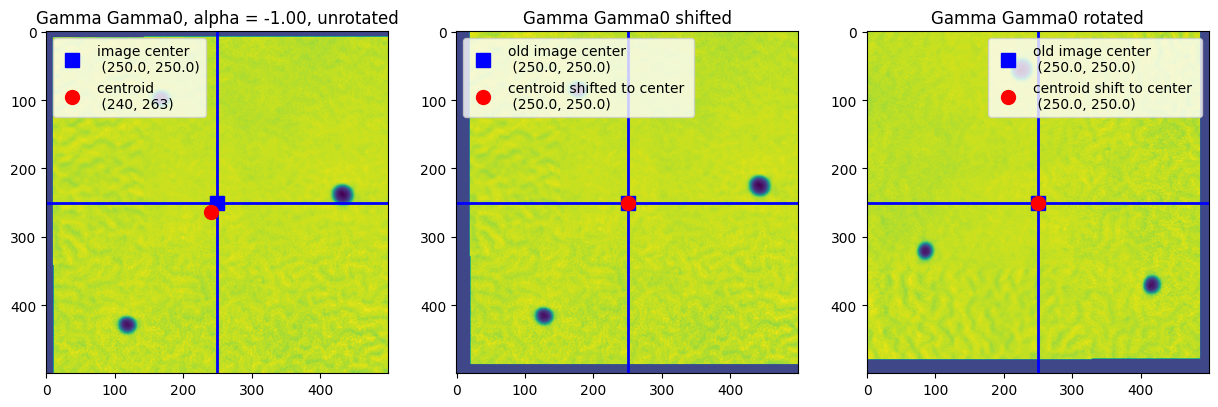

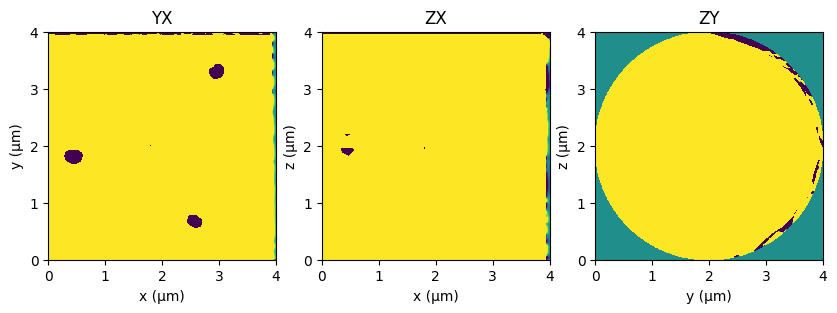

In [58]:
vertical_angle = 90
k = k0

rotated_0 = reconstruct.rotate_about_COR(proj[k], vertical_angle, yo_0, xo_0, ang_deg[k], sample, Gamma, order=3, plot = True)

rotated = [ ]
for i in range(proj.shape[0]):
    rotated_00 = reconstruct.rotate_about_COR(proj[i], vertical_angle, yo_0, xo_0, ang_deg[i],  sample, Gamma, order=3, plot = False)
    rotated.append(rotated_00)
rotated = np.array(rotated)


### quick tomography check 
center2 = center1 #+13
n_iter = 50
model = mbirjax.ParallelBeamModel(proj.shape, ang)
recon, recon_params = model.recon(rotated, num_iterations = n_iter)

reconstruct.plot_crosssections(center1, recon)


FINAL RECON  sharpness=0  snr_db=30  COR shift=-5
Available GPU memory = 26.376GB.
Estimated memory required = 5.958GB full, 3.490GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=12.6850
Relative step size (alpha)=0.28, Error sino RMSE=0.3768
After iteration 1: Pct change=17.5719, Forward loss=10.2837
Relative step size (alpha)=1.24, Error sino RMSE=0.3055
After iteration 2: Pct change=5.0758, Forward loss=9.8713
Relative step size (alpha)=1.50, Error sino RMSE=0.2932
After iteration 3: Pct change=1.6655, Forward loss=9.7362
Relative step size (alpha)=1.50, Error sino RMSE=0.2892
After iteration 4: Pct change=0.7221, Forward loss=9.6683
Relative step size (alpha)=1.50, Error sino RMSE=0.2872
After iteration 5: Pct change=0.3720, Forward loss=9.6279
Relative step size (alpha)=1.50, Error sino RMSE=0.2860
After iteration 6: Pct c

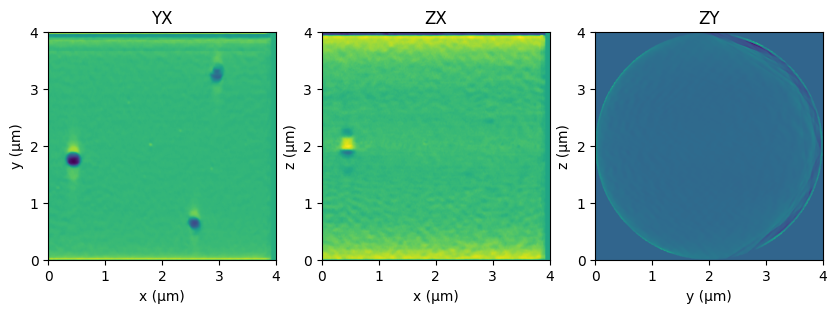

In [59]:
# ── 6. Final reconstruction with chosen parameters ─────────────────────────
n_iter = 30
rotated_best = np.roll(rotated, best_cor_shift, axis=2)

print("\n" + "=" * 60)
print(f"FINAL RECON  sharpness={best_sharpness}  snr_db={best_snr_db}  COR shift={best_cor_shift:+d}")
print("=" * 60)

model_final = mbirjax.ParallelBeamModel(rotated_best.shape, ang)
model_final.set_params(sharpness=float(best_sharpness), snr_db=float(best_snr_db))

recon_final, recon_params_final = model_final.recon(rotated_best, num_iterations=n_iter)

reconstruct.plot_crosssections(center1, recon_final)
print("\nFinal recon_params:", recon_params_final)

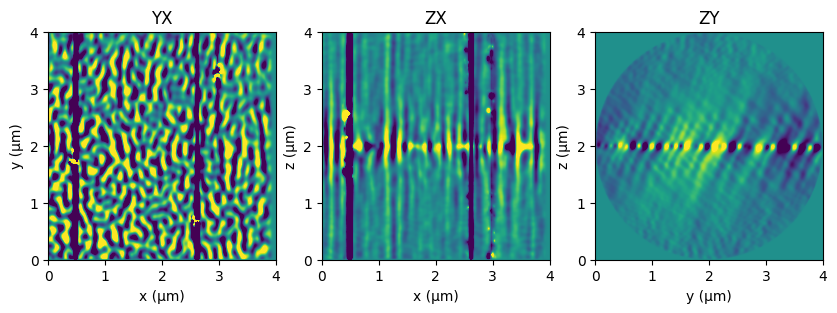

In [56]:
import matplotlib as mpl
def plot_crosssections (k, reconstruction): 
  
     # --- Extract Nx, Ny ---
    Nz, Ny, Nx = reconstruction.shape 

    # --- Define physical extent in μm ---
    FOV_x = 4.0  # μm
    FOV_y = 4.0  # μm

    extent = [0, FOV_x, 0, FOV_y]  # [xmin, xmax, ymin, ymax] in μm

    # Tick positions every 1 μm
    ticks_um = np.arange(0, (FOV_x+0.1), 1.0)

    norm = mpl.colors.Normalize(vmin=-0.00001, vmax=0.00001)
    # --- Plot ---
    fig = plt.figure(figsize=(10, 6))

    ax1 = fig.add_subplot(1, 3, 1)
    ax1.imshow(reconstruction[k,:,:], norm = norm, extent = extent, origin = 'lower')
    ax1.set_title(f'YX')
    ax1.set_ylabel("y (μm)")
    ax1.set_yticks(ticks_um)
    ax1.set_xlabel("x (μm)")
    ax1.set_xticks(ticks_um)
    
    ax2 = fig.add_subplot(1, 3, 2)
    ax2.imshow(reconstruction[:,k,:], norm = norm, extent = extent, origin = 'lower')
    ax2.set_title('ZX')
    ax2.set_ylabel("z (μm)")
    ax2.set_yticks(ticks_um)
    ax2.set_xlabel("x (μm)")
    ax2.set_xticks(ticks_um)
    
    ax3 = fig.add_subplot(1, 3, 3)
    ax3.imshow(reconstruction[:,:,k], norm = norm, extent = extent, origin = 'lower')
    ax3.set_title('ZY')
    ax3.set_ylabel("z (μm)")
    ax3.set_yticks(ticks_um)
    ax3.set_xlabel("y (μm)")
    ax3.set_xticks(ticks_um)


plot_crosssections(center1, recon_final)

247


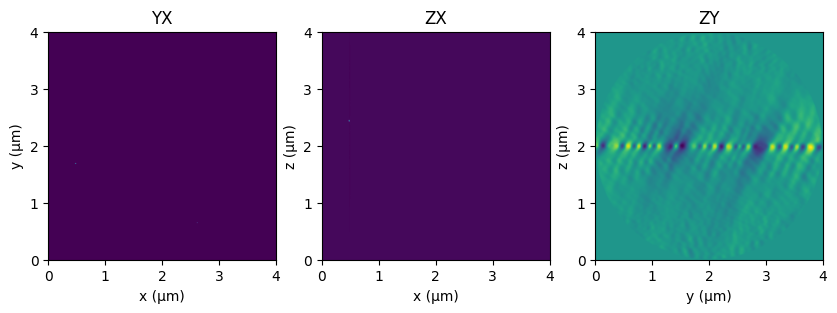

In [45]:
shift_list = [-10] 

for s in shift_list: 
    k = center1 + s
    print(k)
    reconstruct.plot_crosssections (k, recon_final)

# tests

COR SWEEP
Available GPU memory = 26.057GB.
Estimated memory required = 5.958GB full, 3.490GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=28.2577
Relative step size (alpha)=0.72, Error sino RMSE=0.0826
After iteration 1: Pct change=67.5098, Forward loss=21.8477
Relative step size (alpha)=1.43, Error sino RMSE=0.0638
After iteration 2: Pct change=34.4609, Forward loss=15.9257
Relative step size (alpha)=1.50, Error sino RMSE=0.0465
After iteration 3: Pct change=8.7069, Forward loss=14.0680
Relative step size (alpha)=1.50, Error sino RMSE=0.0411
After iteration 4: Pct change=1.8364, Forward loss=13.5542
Relative step size (alpha)=1.50, Error sino RMSE=0.0396
After iteration 5: Pct change=0.5041, Forward loss=13.3208
Relative step size (alpha)=1.50, Error sino RMSE=0.0389
After iteration 6: Pct change=0.2032, Forward loss=13.1837
R

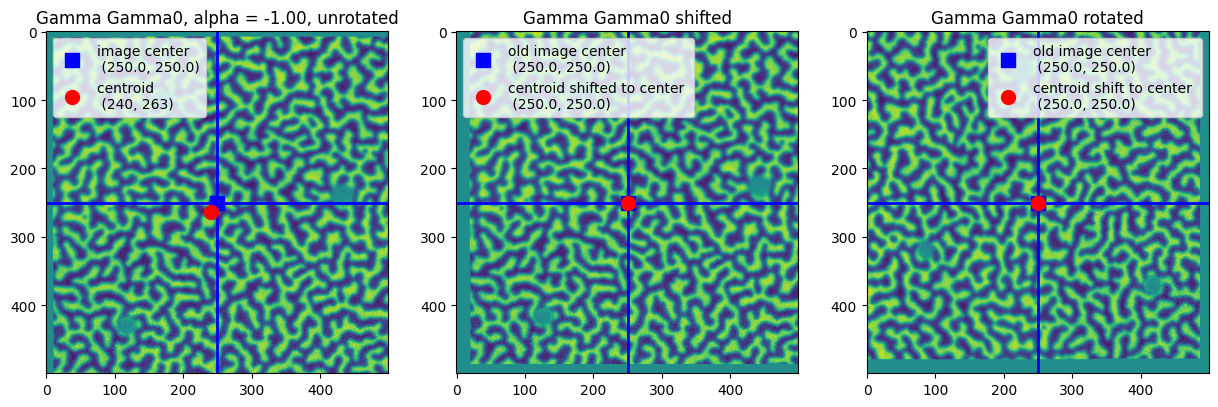

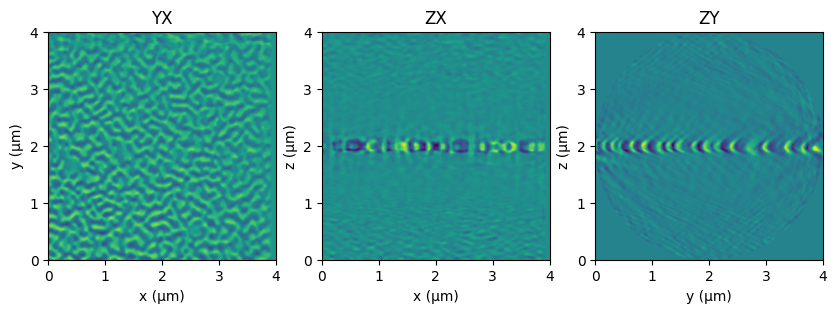

Available GPU memory = 28.485GB.
Estimated memory required = 5.958GB full, 3.490GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=28.2523
Relative step size (alpha)=0.72, Error sino RMSE=0.0826
After iteration 1: Pct change=68.4192, Forward loss=21.6626
Relative step size (alpha)=1.43, Error sino RMSE=0.0633
After iteration 2: Pct change=35.4497, Forward loss=15.6878
Relative step size (alpha)=1.50, Error sino RMSE=0.0458
After iteration 3: Pct change=8.3478, Forward loss=13.9885
Relative step size (alpha)=1.50, Error sino RMSE=0.0409
After iteration 4: Pct change=1.7819, Forward loss=13.5041
Relative step size (alpha)=1.50, Error sino RMSE=0.0395
After iteration 5: Pct change=0.4954, Forward loss=13.2752
Relative step size (alpha)=1.50, Error sino RMSE=0.0388
After iteration 6: Pct change=0.2000, Forward loss=13.1397
Relative st

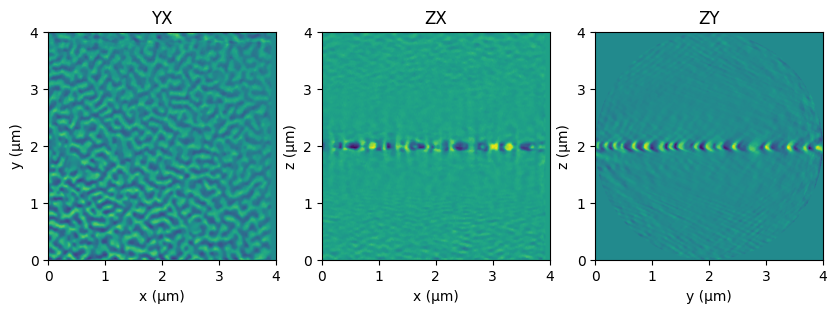

Available GPU memory = 28.485GB.
Estimated memory required = 5.958GB full, 3.490GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=28.2462
Relative step size (alpha)=0.72, Error sino RMSE=0.0825
After iteration 1: Pct change=69.1811, Forward loss=21.4701
Relative step size (alpha)=1.43, Error sino RMSE=0.0627
After iteration 2: Pct change=36.9521, Forward loss=15.3830
Relative step size (alpha)=1.50, Error sino RMSE=0.0449
After iteration 3: Pct change=7.8700, Forward loss=13.8823
Relative step size (alpha)=1.50, Error sino RMSE=0.0406
After iteration 4: Pct change=1.6645, Forward loss=13.4355
Relative step size (alpha)=1.50, Error sino RMSE=0.0393
After iteration 5: Pct change=0.4718, Forward loss=13.2127
Relative step size (alpha)=1.50, Error sino RMSE=0.0386
After iteration 6: Pct change=0.1936, Forward loss=13.0783
Relative st

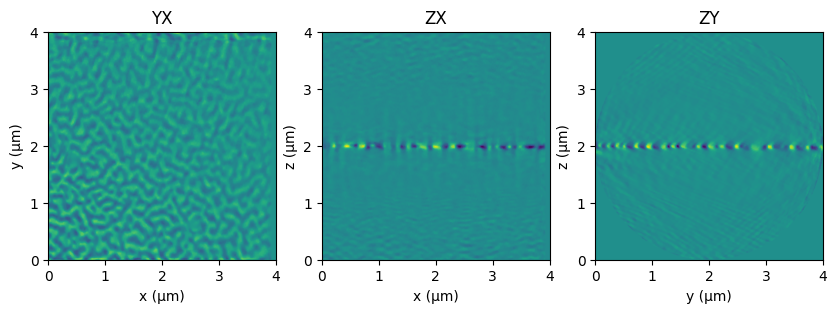

Available GPU memory = 28.485GB.
Estimated memory required = 5.958GB full, 3.490GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=28.2374
Relative step size (alpha)=0.72, Error sino RMSE=0.0825
After iteration 1: Pct change=69.4541, Forward loss=21.3885
Relative step size (alpha)=1.44, Error sino RMSE=0.0625
After iteration 2: Pct change=37.3277, Forward loss=15.2428
Relative step size (alpha)=1.50, Error sino RMSE=0.0445
After iteration 3: Pct change=7.8559, Forward loss=13.7881
Relative step size (alpha)=1.50, Error sino RMSE=0.0403
After iteration 4: Pct change=1.6379, Forward loss=13.3500
Relative step size (alpha)=1.50, Error sino RMSE=0.0390
After iteration 5: Pct change=0.4668, Forward loss=13.1282
Relative step size (alpha)=1.50, Error sino RMSE=0.0384
After iteration 6: Pct change=0.1927, Forward loss=12.9940
Relative st

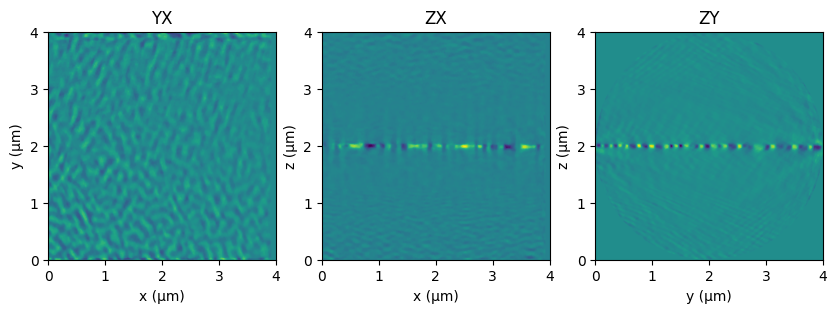

Available GPU memory = 28.392GB.
Estimated memory required = 5.958GB full, 3.490GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=28.2285
Relative step size (alpha)=0.72, Error sino RMSE=0.0825
After iteration 1: Pct change=68.8228, Forward loss=21.4979
Relative step size (alpha)=1.43, Error sino RMSE=0.0628
After iteration 2: Pct change=36.0822, Forward loss=15.3905
Relative step size (alpha)=1.50, Error sino RMSE=0.0450
After iteration 3: Pct change=8.0817, Forward loss=13.7546
Relative step size (alpha)=1.50, Error sino RMSE=0.0402
After iteration 4: Pct change=1.7190, Forward loss=13.2788
Relative step size (alpha)=1.50, Error sino RMSE=0.0388
After iteration 5: Pct change=0.4817, Forward loss=13.0499
Relative step size (alpha)=1.50, Error sino RMSE=0.0381
After iteration 6: Pct change=0.1956, Forward loss=12.9142
Relative st

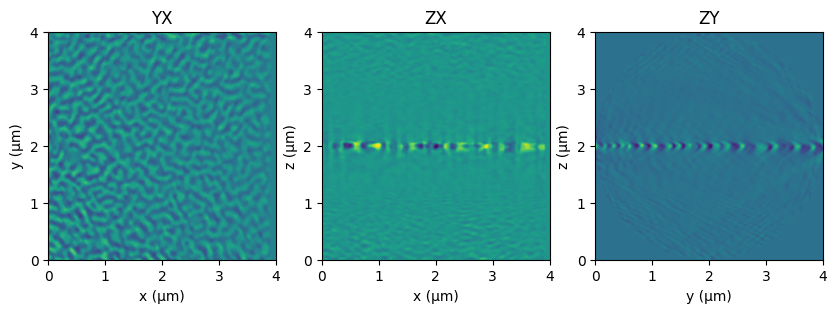

Available GPU memory = 28.485GB.
Estimated memory required = 5.958GB full, 3.490GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=28.2252
Relative step size (alpha)=0.72, Error sino RMSE=0.0825
After iteration 1: Pct change=67.9834, Forward loss=21.6466
Relative step size (alpha)=1.43, Error sino RMSE=0.0633
After iteration 2: Pct change=34.9069, Forward loss=15.5756
Relative step size (alpha)=1.50, Error sino RMSE=0.0455
After iteration 3: Pct change=8.5726, Forward loss=13.7318
Relative step size (alpha)=1.50, Error sino RMSE=0.0401
After iteration 4: Pct change=1.8242, Forward loss=13.2129
Relative step size (alpha)=1.50, Error sino RMSE=0.0386
After iteration 5: Pct change=0.5051, Forward loss=12.9735
Relative step size (alpha)=1.50, Error sino RMSE=0.0379
After iteration 6: Pct change=0.2039, Forward loss=12.8321
Relative st

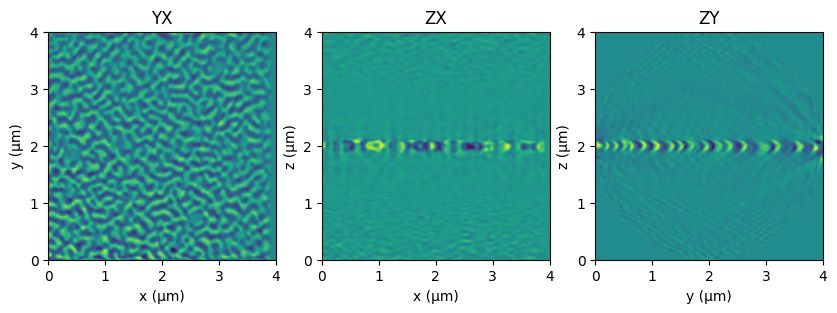

Available GPU memory = 28.485GB.
Estimated memory required = 5.958GB full, 3.490GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=28.2272
Relative step size (alpha)=0.72, Error sino RMSE=0.0825
After iteration 1: Pct change=67.2958, Forward loss=21.7759
Relative step size (alpha)=1.43, Error sino RMSE=0.0636
After iteration 2: Pct change=34.1223, Forward loss=15.7368
Relative step size (alpha)=1.50, Error sino RMSE=0.0460
After iteration 3: Pct change=8.8112, Forward loss=13.7640
Relative step size (alpha)=1.50, Error sino RMSE=0.0402
After iteration 4: Pct change=1.8822, Forward loss=13.2148
Relative step size (alpha)=1.50, Error sino RMSE=0.0386
After iteration 5: Pct change=0.5171, Forward loss=12.9675
Relative step size (alpha)=1.50, Error sino RMSE=0.0379
After iteration 6: Pct change=0.2080, Forward loss=12.8220
Relative st

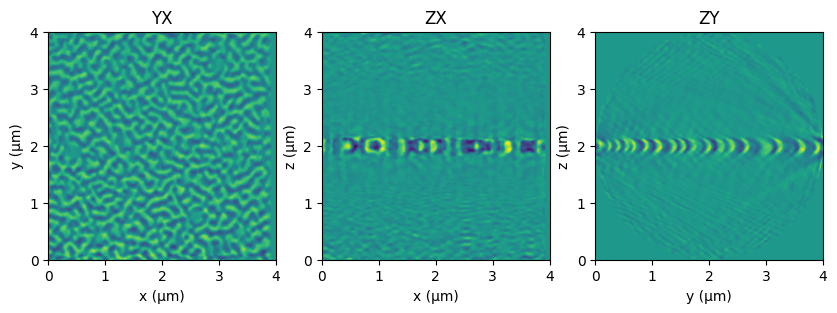

Available GPU memory = 28.485GB.
Estimated memory required = 5.958GB full, 3.490GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=28.2332
Relative step size (alpha)=0.72, Error sino RMSE=0.0825
After iteration 1: Pct change=66.9190, Forward loss=21.8581
Relative step size (alpha)=1.43, Error sino RMSE=0.0639
After iteration 2: Pct change=33.4930, Forward loss=15.8814
Relative step size (alpha)=1.50, Error sino RMSE=0.0464
After iteration 3: Pct change=8.7764, Forward loss=13.8500
Relative step size (alpha)=1.50, Error sino RMSE=0.0405
After iteration 4: Pct change=1.9376, Forward loss=13.2698
Relative step size (alpha)=1.50, Error sino RMSE=0.0388
After iteration 5: Pct change=0.5347, Forward loss=13.0149
Relative step size (alpha)=1.50, Error sino RMSE=0.0380
After iteration 6: Pct change=0.2122, Forward loss=12.8681
Relative st

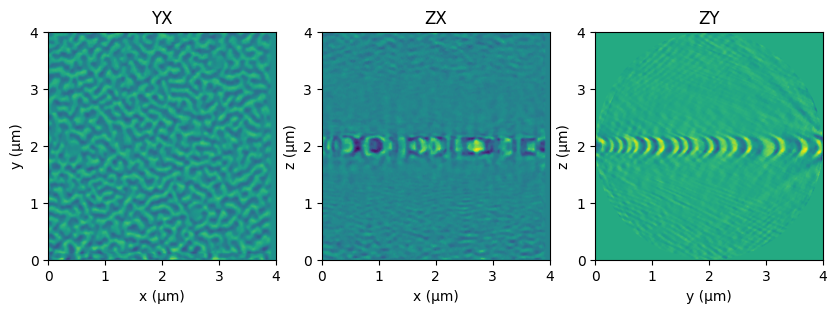

Available GPU memory = 28.485GB.
Estimated memory required = 5.958GB full, 3.490GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=28.2415
Relative step size (alpha)=0.72, Error sino RMSE=0.0825
After iteration 1: Pct change=66.5518, Forward loss=21.9453
Relative step size (alpha)=1.43, Error sino RMSE=0.0641
After iteration 2: Pct change=33.0197, Forward loss=16.0297
Relative step size (alpha)=1.50, Error sino RMSE=0.0468
After iteration 3: Pct change=8.7745, Forward loss=13.9500
Relative step size (alpha)=1.50, Error sino RMSE=0.0408
After iteration 4: Pct change=1.9785, Forward loss=13.3395
Relative step size (alpha)=1.50, Error sino RMSE=0.0390
After iteration 5: Pct change=0.5507, Forward loss=13.0749
Relative step size (alpha)=1.50, Error sino RMSE=0.0382
After iteration 6: Pct change=0.2175, Forward loss=12.9249
Relative st

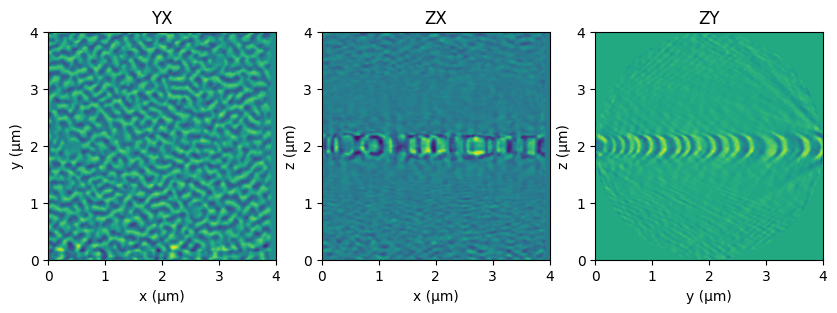

In [34]:
vertical_angle = 90
k = k0

# --- COR shift parameters ---
cor_shifts = np.arange(-20, 21, 5)  # shifts in pixels to sweep over; adjust range as needed

# --- MBIR quality parameter sweep ---
sharpness_values = [-1, 0, 1, 2]
snr_db_values    = [20, 30, 40]

# ── 1. Rotate a single frame for a quick sanity check ──────────────────────
rotated_0 = reconstruct.rotate_about_COR(
    proj[k], vertical_angle, yo_0, xo_0, ang_deg[k], sample, Gamma,
    order=3, plot=True
)

# ── 2. Rotate all projections ───────────────────────────────────────────────
rotated = []
for i in range(proj.shape[0]):
    rotated_00 = reconstruct.rotate_about_COR(
        proj[i], vertical_angle, yo_0, xo_0, ang_deg[i], sample, Gamma,
        order=3, plot=False
    )
    rotated.append(rotated_00)
rotated = np.array(rotated)

# ── 3. COR sweep ────────────────────────────────────────────────────────────
print("=" * 60)
print("COR SWEEP")
print("=" * 60)

n_iter   = 20
n_views, n_slices, n_channels = rotated.shape


for shift in cor_shifts:
    # Roll the sinogram horizontally to emulate a COR shift
    rotated_shifted = np.roll(rotated, shift, axis=2)

    model = mbirjax.ParallelBeamModel(rotated_shifted.shape, ang)
    model.set_params(sharpness=0.0, snr_db=30.0)          # neutral defaults for COR sweep

    recon, recon_params = model.recon(rotated_shifted, num_iterations=n_iter)

    print(f"\nCOR shift = {shift:+d} px")
    reconstruct.plot_crosssections(center1, recon)
    plt.show()          # force matplotlib to render the current figure
    plt.pause(0.001)    # small pause to flush the GUI event loop


In [13]:
reconstruct.plot_crosssections(center1, recon)


SHARPNESS × SNR_DB SWEEP
Available GPU memory = 31.898GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=9.2513
Relative step size (alpha)=1.50, Error sino RMSE=0.1296
After iteration 1: Pct change=42.4784, Forward loss=9.0988
Relative step size (alpha)=1.50, Error sino RMSE=0.1275
After iteration 2: Pct change=26.3528, Forward loss=8.8843
Relative step size (alpha)=1.50, Error sino RMSE=0.1245
After iteration 3: Pct change=15.2273, Forward loss=8.6524
Relative step size (alpha)=1.50, Error sino RMSE=0.1212
After iteration 4: Pct change=10.0736, Forward loss=8.4091
Relative step size (alpha)=1.50, Error sino RMSE=0.1178
After iteration 5: Pct change=7.5933, Forward loss=8.1516
Relative step size (alpha)=1.50, Error sino RMSE=0.1142
After iteration 6: Pct change=5.9661, Forward lo

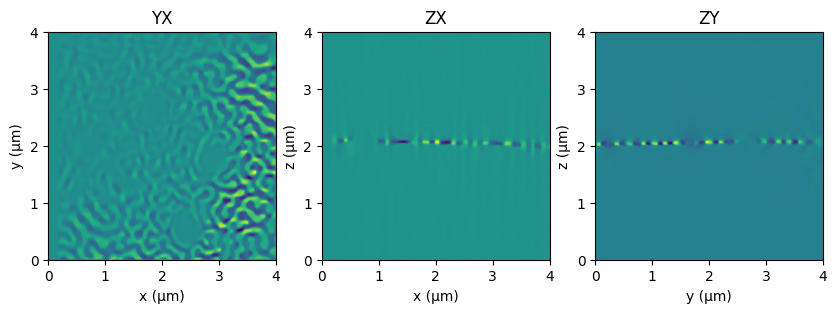

Available GPU memory = 31.898GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=27.7267
Relative step size (alpha)=1.10, Error sino RMSE=0.1229
After iteration 1: Pct change=67.5553, Forward loss=22.8795
Relative step size (alpha)=1.50, Error sino RMSE=0.1014
After iteration 2: Pct change=47.0927, Forward loss=16.3015
Relative step size (alpha)=1.50, Error sino RMSE=0.0722
After iteration 3: Pct change=13.1999, Forward loss=14.7003
Relative step size (alpha)=1.50, Error sino RMSE=0.0651
After iteration 4: Pct change=3.0888, Forward loss=14.3466
Relative step size (alpha)=1.50, Error sino RMSE=0.0636
After iteration 5: Pct change=0.6578, Forward loss=14.1512
Relative step size (alpha)=1.50, Error sino RMSE=0.0627
After iteration 6: Pct change=0.2210, Forward loss=14.0212
Relative s

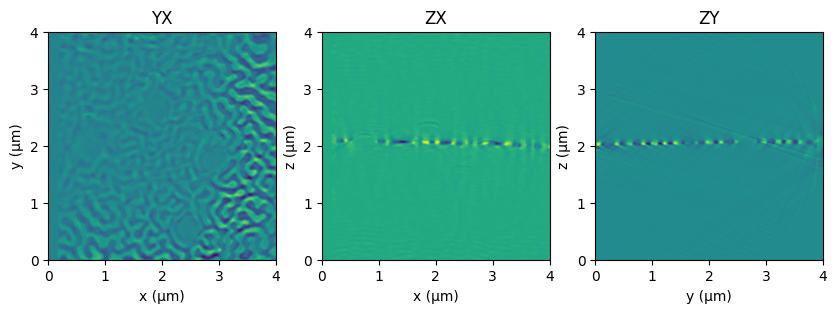

Available GPU memory = 31.392GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=85.1475
Relative step size (alpha)=0.22, Error sino RMSE=0.1193
After iteration 1: Pct change=63.9843, Forward loss=67.6441
Relative step size (alpha)=0.18, Error sino RMSE=0.0948
After iteration 2: Pct change=68.4342, Forward loss=44.3413
Relative step size (alpha)=0.66, Error sino RMSE=0.0621
After iteration 3: Pct change=9.3196, Forward loss=41.3944
Relative step size (alpha)=0.50, Error sino RMSE=0.0580
After iteration 4: Pct change=3.1680, Forward loss=40.2783
Relative step size (alpha)=0.54, Error sino RMSE=0.0564
After iteration 5: Pct change=1.4691, Forward loss=39.7579
Relative step size (alpha)=0.59, Error sino RMSE=0.0557
After iteration 6: Pct change=0.7804, Forward loss=39.4964
Relative st

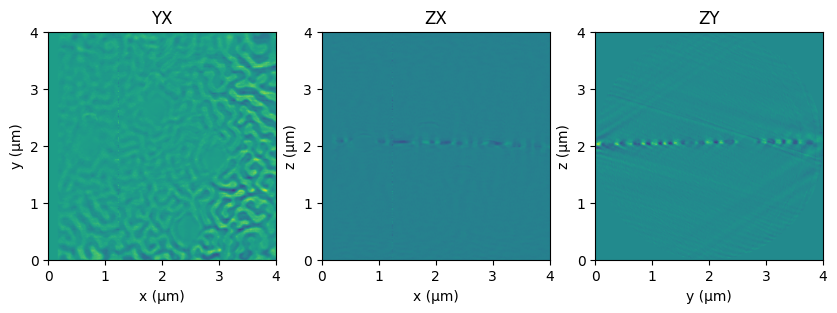

Available GPU memory = 30.886GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=8.9945
Relative step size (alpha)=1.50, Error sino RMSE=0.1260
After iteration 1: Pct change=44.7844, Forward loss=8.4738
Relative step size (alpha)=1.50, Error sino RMSE=0.1187
After iteration 2: Pct change=29.7710, Forward loss=7.7295
Relative step size (alpha)=1.50, Error sino RMSE=0.1083
After iteration 3: Pct change=19.3233, Forward loss=6.9068
Relative step size (alpha)=1.50, Error sino RMSE=0.0968
After iteration 4: Pct change=12.6477, Forward loss=6.1439
Relative step size (alpha)=1.50, Error sino RMSE=0.0861
After iteration 5: Pct change=6.6630, Forward loss=5.6036
Relative step size (alpha)=1.50, Error sino RMSE=0.0785
After iteration 6: Pct change=2.7898, Forward loss=5.2914
Relative step si

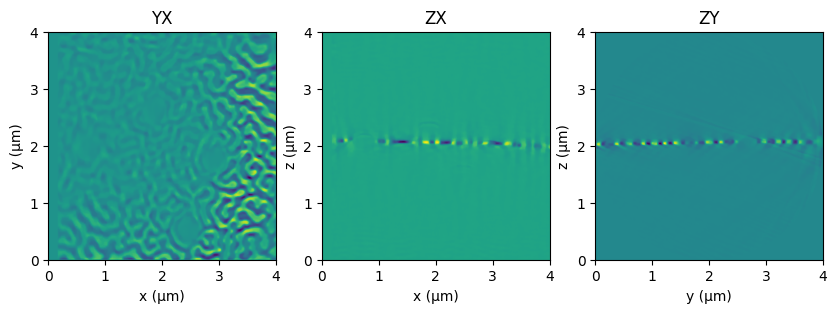

Available GPU memory = 30.380GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=27.0456
Relative step size (alpha)=0.47, Error sino RMSE=0.1198
After iteration 1: Pct change=64.4450, Forward loss=21.4266
Relative step size (alpha)=0.62, Error sino RMSE=0.0949
After iteration 2: Pct change=53.3389, Forward loss=14.2102
Relative step size (alpha)=1.50, Error sino RMSE=0.0630
After iteration 3: Pct change=10.6014, Forward loss=13.3694
Relative step size (alpha)=1.50, Error sino RMSE=0.0592
After iteration 4: Pct change=2.1054, Forward loss=13.1040
Relative step size (alpha)=1.50, Error sino RMSE=0.0581
After iteration 5: Pct change=0.6040, Forward loss=12.9788
Relative step size (alpha)=1.50, Error sino RMSE=0.0575
After iteration 6: Pct change=0.2401, Forward loss=12.9089
Relative s

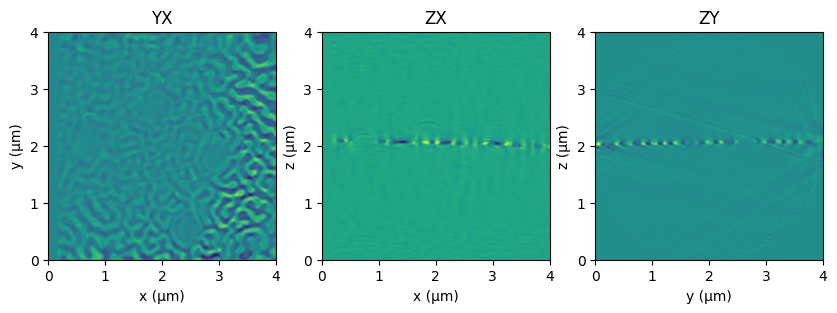

Available GPU memory = 29.874GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=85.0525
Relative step size (alpha)=0.07, Error sino RMSE=0.1192
After iteration 1: Pct change=59.5700, Forward loss=68.6801
Relative step size (alpha)=0.07, Error sino RMSE=0.0962
After iteration 2: Pct change=71.6685, Forward loss=43.5937
Relative step size (alpha)=0.41, Error sino RMSE=0.0611
After iteration 3: Pct change=9.9011, Forward loss=40.3538
Relative step size (alpha)=0.44, Error sino RMSE=0.0565
After iteration 4: Pct change=2.3867, Forward loss=39.5228
Relative step size (alpha)=0.48, Error sino RMSE=0.0554
After iteration 5: Pct change=0.8405, Forward loss=39.2195
Relative step size (alpha)=0.49, Error sino RMSE=0.0550
After iteration 6: Pct change=0.4563, Forward loss=39.0617
Relative st

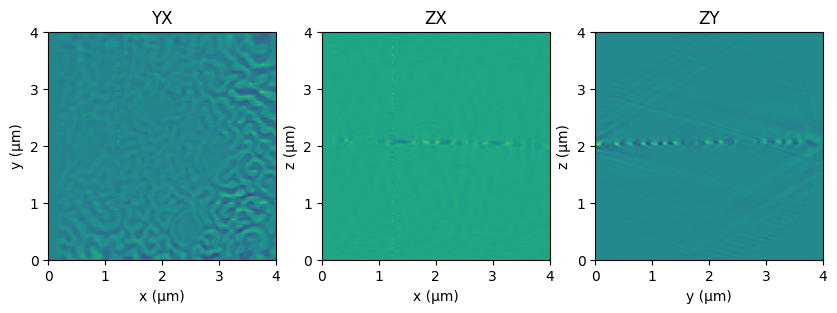

Available GPU memory = 29.368GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=8.6687
Relative step size (alpha)=0.87, Error sino RMSE=0.1215
After iteration 1: Pct change=59.8320, Forward loss=7.1662
Relative step size (alpha)=1.48, Error sino RMSE=0.1004
After iteration 2: Pct change=31.9446, Forward loss=5.5772
Relative step size (alpha)=1.50, Error sino RMSE=0.0782
After iteration 3: Pct change=11.7350, Forward loss=4.8438
Relative step size (alpha)=1.50, Error sino RMSE=0.0679
After iteration 4: Pct change=2.4891, Forward loss=4.6604
Relative step size (alpha)=1.50, Error sino RMSE=0.0653
After iteration 5: Pct change=0.5565, Forward loss=4.5903
Relative step size (alpha)=1.50, Error sino RMSE=0.0643
After iteration 6: Pct change=0.1856, Forward loss=4.5496
Relative step siz

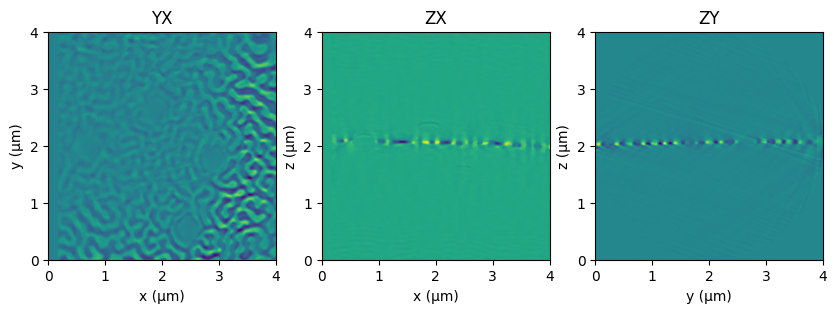

Available GPU memory = 28.862GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=26.9070
Relative step size (alpha)=0.15, Error sino RMSE=0.1192
After iteration 1: Pct change=60.4432, Forward loss=21.6187
Relative step size (alpha)=0.19, Error sino RMSE=0.0958
After iteration 2: Pct change=66.6164, Forward loss=13.8405
Relative step size (alpha)=0.94, Error sino RMSE=0.0613
After iteration 3: Pct change=8.0920, Forward loss=13.1097
Relative step size (alpha)=0.61, Error sino RMSE=0.0581
After iteration 4: Pct change=3.4244, Forward loss=12.7937
Relative step size (alpha)=0.72, Error sino RMSE=0.0567
After iteration 5: Pct change=1.5971, Forward loss=12.6521
Relative step size (alpha)=0.72, Error sino RMSE=0.0561
After iteration 6: Pct change=1.0228, Forward loss=12.5726
Relative st

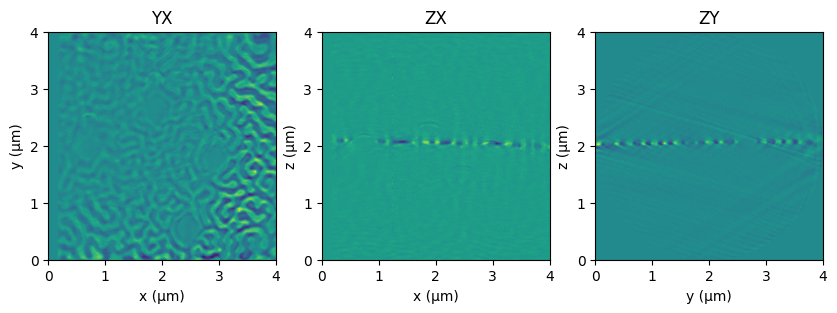

Available GPU memory = 28.357GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=85.0516
Relative step size (alpha)=0.02, Error sino RMSE=0.1192
After iteration 1: Pct change=56.9969, Forward loss=69.7117
Relative step size (alpha)=0.03, Error sino RMSE=0.0977
After iteration 2: Pct change=75.0078, Forward loss=42.9939
Relative step size (alpha)=0.29, Error sino RMSE=0.0602
After iteration 3: Pct change=9.9106, Forward loss=39.8091
Relative step size (alpha)=0.42, Error sino RMSE=0.0558
After iteration 4: Pct change=1.8767, Forward loss=39.2040
Relative step size (alpha)=0.46, Error sino RMSE=0.0549
After iteration 5: Pct change=0.6551, Forward loss=38.9853
Relative step size (alpha)=0.46, Error sino RMSE=0.0546
After iteration 6: Pct change=0.3384, Forward loss=38.8658
Relative st

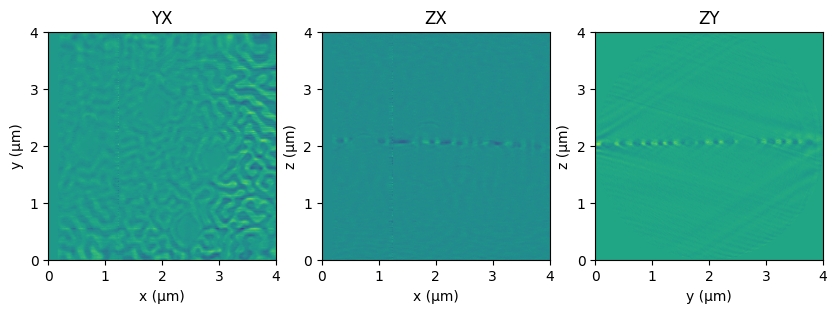

Available GPU memory = 27.851GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=8.5270
Relative step size (alpha)=0.33, Error sino RMSE=0.1195
After iteration 1: Pct change=60.6124, Forward loss=6.8096
Relative step size (alpha)=0.58, Error sino RMSE=0.0954
After iteration 2: Pct change=44.8517, Forward loss=4.5847
Relative step size (alpha)=1.50, Error sino RMSE=0.0642
After iteration 3: Pct change=6.1352, Forward loss=4.3151
Relative step size (alpha)=1.50, Error sino RMSE=0.0605
After iteration 4: Pct change=1.1530, Forward loss=4.2463
Relative step size (alpha)=1.50, Error sino RMSE=0.0595
After iteration 5: Pct change=0.3275, Forward loss=4.2122
Relative step size (alpha)=1.50, Error sino RMSE=0.0590
After iteration 6: Pct change=0.1399, Forward loss=4.1920
Relative step size

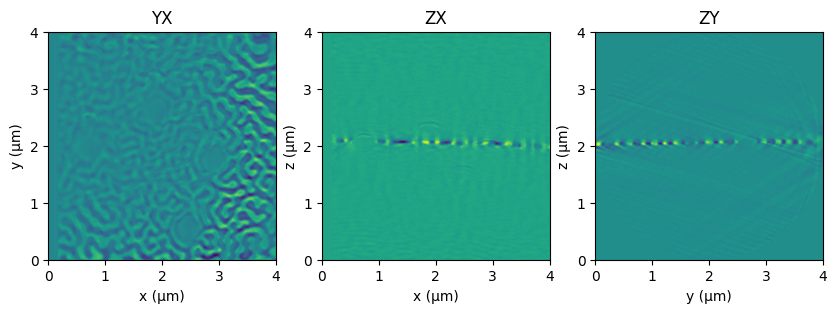

Available GPU memory = 27.345GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=26.8950
Relative step size (alpha)=0.04, Error sino RMSE=0.1192
After iteration 1: Pct change=57.6560, Forward loss=21.9425
Relative step size (alpha)=0.07, Error sino RMSE=0.0972
After iteration 2: Pct change=71.9497, Forward loss=13.7186
Relative step size (alpha)=0.49, Error sino RMSE=0.0608
After iteration 3: Pct change=8.9360, Forward loss=12.7974
Relative step size (alpha)=0.48, Error sino RMSE=0.0567
After iteration 4: Pct change=2.5383, Forward loss=12.5333
Relative step size (alpha)=0.54, Error sino RMSE=0.0555
After iteration 5: Pct change=0.9380, Forward loss=12.4359
Relative step size (alpha)=0.53, Error sino RMSE=0.0551
After iteration 6: Pct change=0.5436, Forward loss=12.3857
Relative st

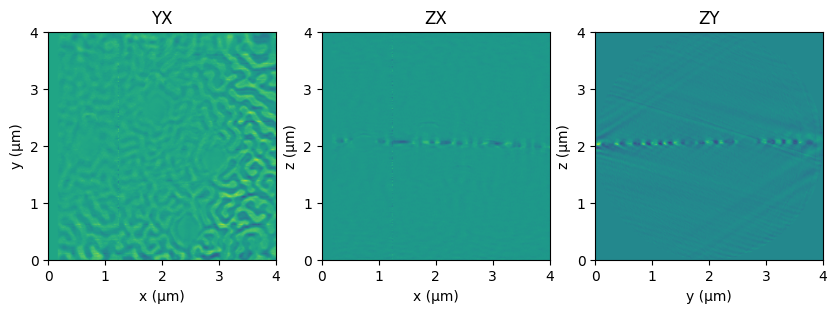

Available GPU memory = 26.839GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=85.0620
Relative step size (alpha)=0.01, Error sino RMSE=0.1192
After iteration 1: Pct change=55.7577, Forward loss=70.4776
Relative step size (alpha)=0.02, Error sino RMSE=0.0988
After iteration 2: Pct change=77.7443, Forward loss=42.6127
Relative step size (alpha)=0.25, Error sino RMSE=0.0597
After iteration 3: Pct change=9.4228, Forward loss=39.5875
Relative step size (alpha)=0.42, Error sino RMSE=0.0555
After iteration 4: Pct change=1.5243, Forward loss=39.0886
Relative step size (alpha)=0.43, Error sino RMSE=0.0548
After iteration 5: Pct change=0.5424, Forward loss=38.9004
Relative step size (alpha)=0.43, Error sino RMSE=0.0545
After iteration 6: Pct change=0.3279, Forward loss=38.7848
Relative st

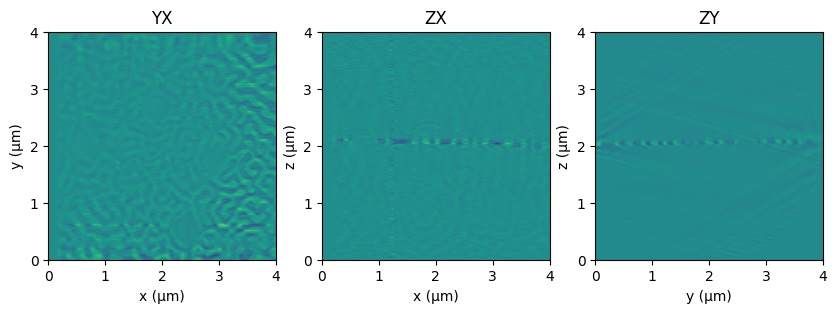

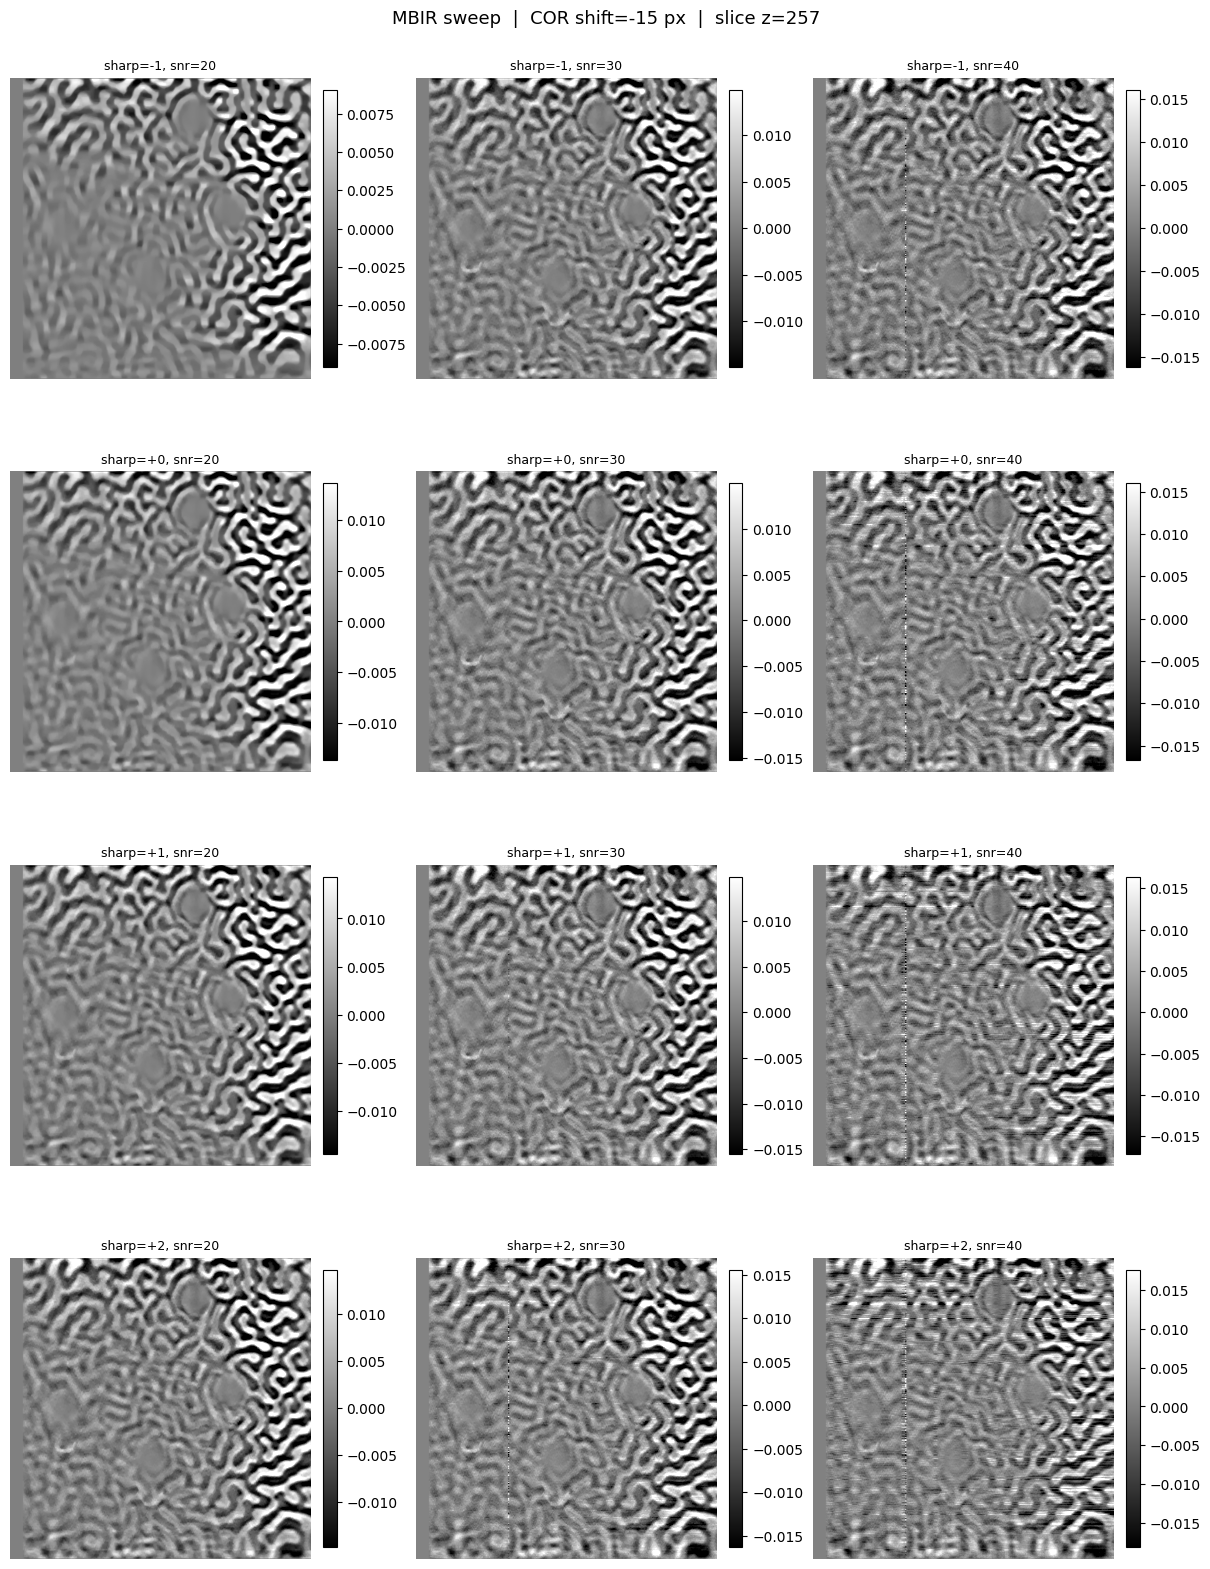

In [10]:
# ── 4. MBIR parameter sweep (sharpness × snr_db) ───────────────────────────
# Use the best COR shift you identified above; update best_cor_shift accordingly
best_cor_shift = -15   # <── update after inspecting COR sweep results

rotated_best = np.roll(rotated, best_cor_shift, axis=2)

print("\n" + "=" * 60)
print("SHARPNESS × SNR_DB SWEEP")
print("=" * 60)

results = {}   # store every reconstruction for later comparison

for sharpness in sharpness_values:
    for snr_db in snr_db_values:

        model = mbirjax.ParallelBeamModel(rotated_best.shape, ang)
        model.set_params(sharpness=float(sharpness), snr_db=float(snr_db))

        recon, recon_params = model.recon(rotated_best, num_iterations=n_iter)

        key = (sharpness, snr_db)
        results[key] = recon

        print(f"\nsharpness={sharpness:+d}  snr_db={snr_db}")
        reconstruct.plot_crosssections(center1, recon)

        plt.show()          # force matplotlib to render the current figure
        plt.pause(0.001)    # small pause to flush the GUI event loop

# ── 5. Side-by-side summary figure ─────────────────────────────────────────
n_sharp = len(sharpness_values)
n_snr   = len(snr_db_values)

# Pick the central slice for the summary mosaic
z_mid = recon.shape[0] // 2

fig, axes = plt.subplots(
    n_sharp, n_snr,
    figsize=(4 * n_snr, 4 * n_sharp),
    constrained_layout=True
)
fig.suptitle(f"MBIR sweep  |  COR shift={best_cor_shift:+d} px  |  slice z={z_mid}",
             fontsize=13)

for r, sharpness in enumerate(sharpness_values):
    for c, snr_db in enumerate(snr_db_values):
        ax  = axes[r, c]
        vol = results[(sharpness, snr_db)]
        im  = ax.imshow(vol[z_mid], cmap="gray",
                        vmin=np.percentile(vol[z_mid], 2),
                        vmax=np.percentile(vol[z_mid], 98))
        ax.set_title(f"sharp={sharpness:+d}, snr={snr_db}", fontsize=9)
        ax.axis("off")
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# plt.savefig("mbir_param_sweep.png", dpi=150)
plt.show()




FINAL RECON  sharpness=0  snr_db=30  COR shift=-15
Available GPU memory = 26.060GB.
Estimated memory required = 6.746GB full, 3.871GB update
Using cuda:0 for main memory, cuda:0 as worker.
views_per_batch = 256; pixels_per_batch = 2048
Computing Hessian diagonal
Starting VCD iterations
After iteration 0: Pct change=100.0000, Forward loss=14.7957
Relative step size (alpha)=0.14, Error sino RMSE=0.7430
After iteration 1: Pct change=30.2294, Forward loss=12.7484
Relative step size (alpha)=0.92, Error sino RMSE=0.6402
After iteration 2: Pct change=14.0234, Forward loss=12.1575
Relative step size (alpha)=1.50, Error sino RMSE=0.6105
After iteration 3: Pct change=3.1958, Forward loss=12.0443
Relative step size (alpha)=1.50, Error sino RMSE=0.6048
After iteration 4: Pct change=0.9864, Forward loss=12.0071
Relative step size (alpha)=1.50, Error sino RMSE=0.6030
After iteration 5: Pct change=0.3730, Forward loss=11.9897
Relative step size (alpha)=1.50, Error sino RMSE=0.6021
After iteration 6:

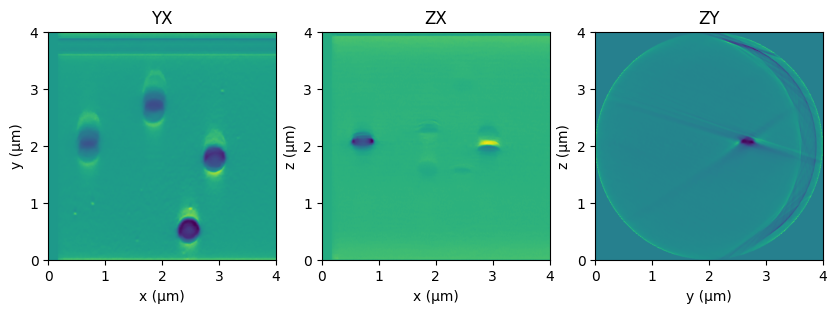

In [22]:
# ── 6. Final reconstruction with chosen parameters ─────────────────────────
best_sharpness = 0    # <── update after inspecting the sweep
best_snr_db    = 30   # <── update after inspecting the sweep
best_cor_shift = -15 
rotated_best = np.roll(rotated, best_cor_shift, axis=2)

print("\n" + "=" * 60)
print(f"FINAL RECON  sharpness={best_sharpness}  snr_db={best_snr_db}  COR shift={best_cor_shift:+d}")
print("=" * 60)

model_final = mbirjax.ParallelBeamModel(rotated_best.shape, ang)
model_final.set_params(sharpness=float(best_sharpness), snr_db=float(best_snr_db))

recon_final, recon_params_final = model_final.recon(rotated_best, num_iterations=n_iter)

reconstruct.plot_crosssections(center1, recon_final)
print("\nFinal recon_params:", recon_params_final)

In [31]:
import tifffile

tifffile.imwrite(
    f"{Gamma}_mbirjax_recon.tif",
    recon.astype(np.float32)
)